# 02 · Aprender de los fotogramas de un solo clip: `un_vaso_dos_grifos`

En vez de entrenar con miles de clips, entrenamos con **los fotogramas de un único clip**, `479183e22a06` (bar_05). Dentro de ese clip marcamos *cuándo* ocurre la mala praxis (hacia 46–52 s el vaso pasa de un grifo a otro). Esos instantes son los positivos y el resto del clip los negativos.

Cómo:
1. Sacamos del clip ventanas cortas de vídeo (16 fotogramas a 4 fps = 4 s), una cada 0,5 s, recortadas a la zona de grifos.
2. Cada ventana pasa por **V-JEPA 2** → un vector global y uno por grifo.
3. Un clasificador lineal aprende "evento / no evento" con esas ~115 ventanas.
4. **Métricas dentro del clip**: ¿acierta en qué segundos ocurre? (dejando fuera las ventanas vecinas para no hacer trampa).
5. **Métricas fuera del clip** (la prueba de verdad): pasamos el detector por otros clips de bar_05 y miramos si los clips etiquetados `un_vaso_dos_grifos` sacan más puntuación que el resto.
6. **Veredicto por clip**: SÍ / NO ha detectado la mala praxis, en qué segundos y con qué confianza, y si coincide con la etiqueta humana.

Aviso honesto: un solo clip es un solo ejemplo del evento. Si el paso 5 sale flojo, lo normal es añadir 3–5 clips más marcados a mano (el notebook lo deja preparado) antes que pasar a todo el dataset.

## 0 · Configuración

In [20]:
import imageio_ffmpeg, os
os.environ['PATH'] = os.path.dirname(imageio_ffmpeg.get_ffmpeg_exe()) + os.pathsep + os.environ['PATH']

In [15]:
import pathlib

# raíz del repo: sube desde la carpeta actual hasta encontrar .git
ROOT = pathlib.Path.cwd().resolve()
while not (ROOT / '.git').exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent

DRIVE = str(ROOT / 'data')       # aquí van train.csv, test.csv y los vídeos
OUT   = str(ROOT / 'out' / 'praxis')
WORK  = str(ROOT / 'out' / 'work')
REF_CLIP = '479183e22a06'
BAR      = 'bar_05'
TARGET   = 'un_vaso_dos_grifos'

# Zona de grifos de bar_05 en píxeles del 896x512 (estimada; se comprueba en el paso 2)
ZONE = [380, 30, 620, 260]
TAPS = [[0.00, 0.0, 0.25, 0.6], [0.25, 0.0, 0.50, 0.6], [0.50, 0.0, 0.75, 0.6], [0.75, 0.0, 1.00, 0.6]]  # relativas a ZONE

# Etiquetas dentro del clip, en segundos. EVENTS = mala praxis; IGNORE = dudoso, no se usa para entrenar ni medir
EVENTS = [(46.0, 52.0)]
IGNORE = [(6.0, 14.0)]      # otro servicio que podría ser también dos grifos; revísalo en el paso 2

# Para añadir más clips marcados a mano más adelante: {clip_id: [(t0, t1), ...]}
EXTRA_LABELED = {}

VJ_MODEL = 'facebook/vjepa2-vitl-fpc64-256'
FPS    = 4      # fotogramas por segundo
WIN    = 16     # fotogramas por ventana (4 s)
STRIDE = 2      # una ventana cada 2 fotogramas = 0,5 s (en el clip de referencia)
STRIDE_SCAN = 4 # una cada 1 s al escanear otros clips (más barato)
N_NEG_SCAN  = 60  # clips normales/otras clases de bar_05 para la prueba fuera del clip (+ todos los positivos)

import os; os.makedirs(OUT, exist_ok=True); os.makedirs(WORK, exist_ok=True)

In [16]:
# Solo actualizamos transformers si hace falta (V-JEPA 2). No toques pandas: rompe google-colab.
import subprocess, sys, transformers
from packaging.version import Version
if Version(transformers.__version__) < Version('4.53'):
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', '-U', 'transformers>=4.53'], check=True)
    print('transformers actualizado: Entorno de ejecución > Reiniciar sesión y vuelve a ejecutar desde arriba')
else:
    print('transformers', transformers.__version__, 'ok')

transformers 5.20.2 ok


## 1 · Encontrar el clip y train.csv en tu Drive

In [17]:
import pathlib, shutil, zipfile, numpy as np, pandas as pd, matplotlib.pyplot as plt
from collections import Counter
from tqdm.auto import tqdm
D = pathlib.Path(DRIVE); assert D.exists(), f'No encuentro {D}'
CLIPS = pathlib.Path(WORK, 'clips'); CLIPS.mkdir(exist_ok=True)

train_csv = sorted(D.rglob('train.csv'), key=lambda q: len(q.parts))
assert train_csv, 'No encuentro train.csv dentro de DRIVE'
train = pd.read_csv(train_csv[0])

# carpeta con más .mp4 (los clips descomprimidos) y, si no, el zip de clips
mp4_dirs = Counter(q.parent for q in D.rglob('*.mp4'))
CLIPS_DIR = mp4_dirs.most_common(1)[0][0] if mp4_dirs else None
CLIPS_ZIP = next((z for z in D.rglob('*.zip') if 'clip' in z.name), None)
print('train.csv:', train_csv[0]); print('clips:', CLIPS_DIR, f'({mp4_dirs[CLIPS_DIR]} .mp4)' if CLIPS_DIR else '', '| zip:', CLIPS_ZIP)

def fetch(cids):
    # copia a /content los clips pedidos (desde la carpeta o desde el zip)
    need = {c for c in cids if not (CLIPS / f'{c}.mp4').exists()}
    if not need: return list(cids)
    dirs = Counter(q.parent for q in D.rglob('*.mp4'))    # se vuelve a buscar: puede que hayas descomprimido después del paso 1
    for d in dirs:                                         # incluye el vídeo suelto de referencia
        for c in list(need):
            if (d / f'{c}.mp4').exists(): shutil.copy(d / f'{c}.mp4', CLIPS / f'{c}.mp4'); need.discard(c)
    if need and CLIPS_ZIP:
        with zipfile.ZipFile(CLIPS_ZIP) as z:
            for n in z.namelist():
                if n.endswith('.mp4') and pathlib.Path(n).stem in need:
                    (CLIPS / f'{pathlib.Path(n).stem}.mp4').write_bytes(z.read(n)); need.discard(pathlib.Path(n).stem)
    if need: print('no encontrados:', len(need))
    return [c for c in cids if (CLIPS / f'{c}.mp4').exists()]

assert fetch([REF_CLIP]), f'No encuentro {REF_CLIP}.mp4 en tu Drive'
print(train[train.clip_id == REF_CLIP])

train.csv: /Users/alejandropallarescuina/Desktop/Universidad/UFV/Cuarto/Hackathon/Hackathon-Gambooza-Carnicos/data/train.csv
clips: /Users/alejandropallarescuina/Desktop/Universidad/UFV/Cuarto/Hackathon/Hackathon-Gambooza-Carnicos/data/clips_public/Train/bar_05/normal (360 .mp4) | zip: None
         clip_id     bar weekday  hour  seconds               label
68  479183e22a06  bar_05     Fri    15     60.0  un_vaso_dos_grifos


## 2 · Mirar el clip y confirmar las etiquetas

Fotogramas del recorte de grifos cada 0,5 s. Ajusta `EVENTS` / `IGNORE` en la celda 0 si ves el evento en otros segundos, y `ZONE` / `TAPS` si las cajas no caen sobre los grifos.

Esto es para poder compilarlo en mac:

In [24]:
import shutil
try:
    import imageio_ffmpeg
    FFMPEG = imageio_ffmpeg.get_ffmpeg_exe()      # ffmpeg dentro del venv
except ImportError:
    FFMPEG = shutil.which('ffmpeg') or 'ffmpeg'   # el del sistema (brew)
print('ffmpeg:', FFMPEG)


ffmpeg: /Users/alejandropallarescuina/Desktop/Universidad/UFV/Cuarto/Hackathon/Hackathon-Gambooza-Carnicos/.venv/lib/python3.13/site-packages/imageio_ffmpeg/binaries/ffmpeg-macos-aarch64-v7.1


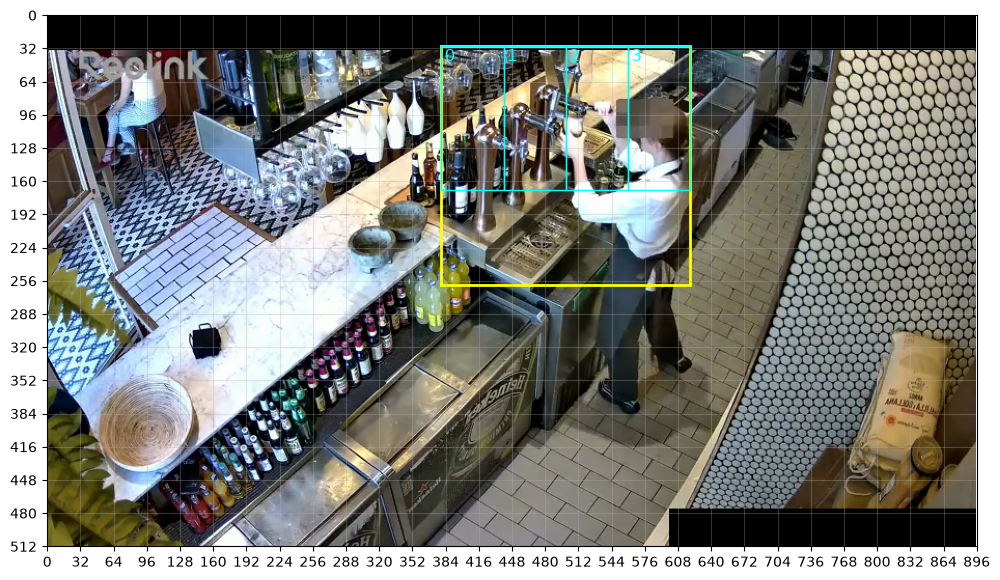

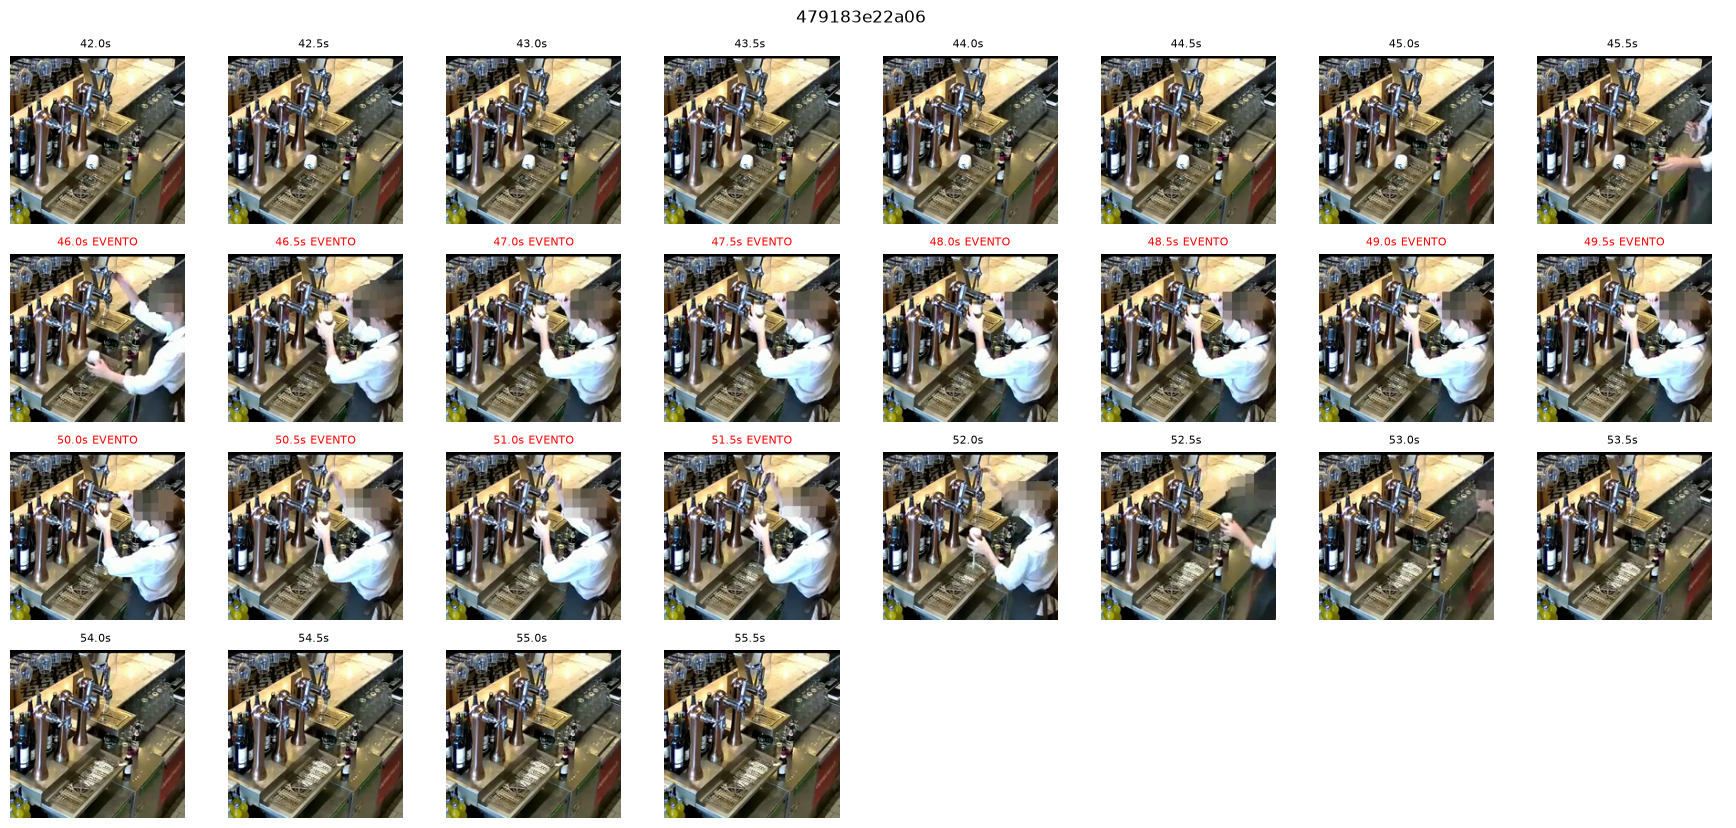

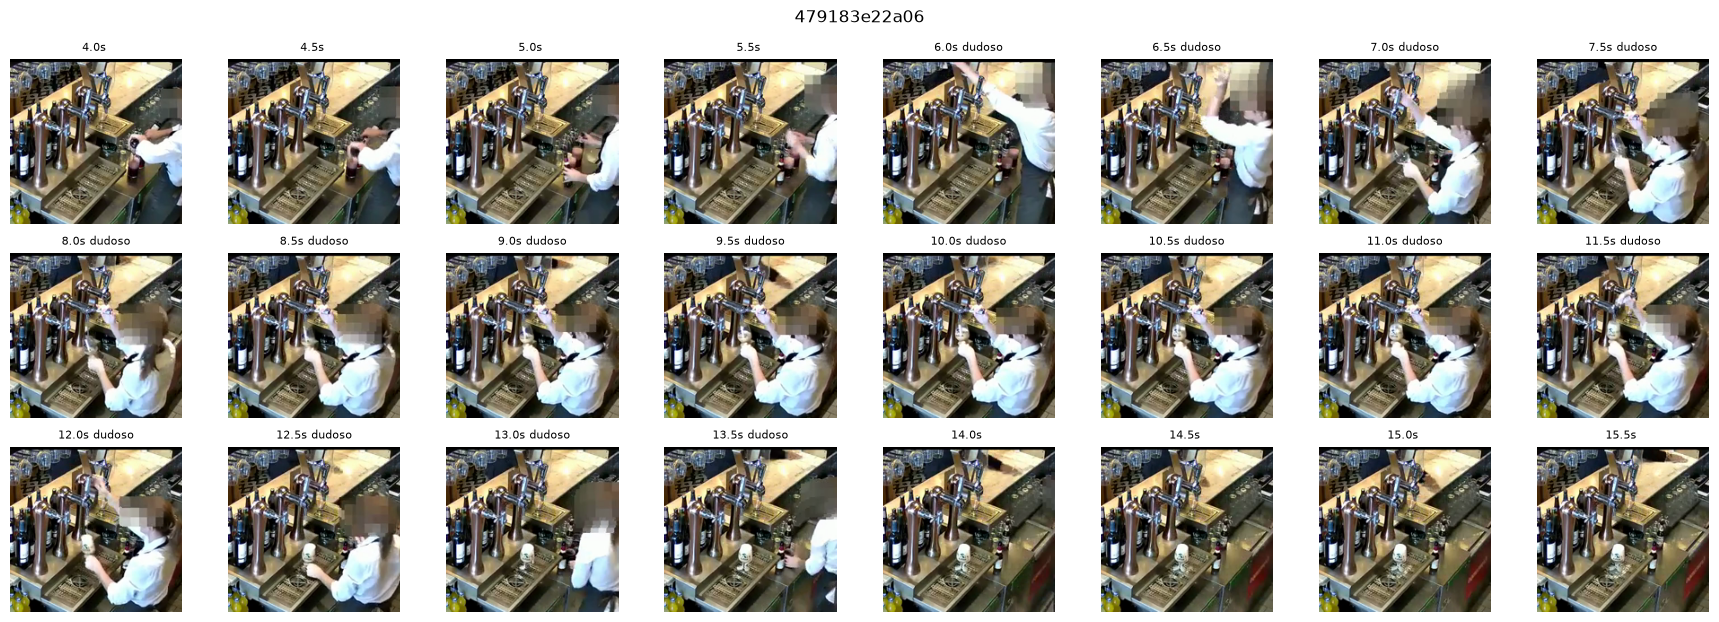

In [25]:
def decode(path, fps, crop=None, size=(256, 256)):
    vf = [f'fps={fps}']
    if crop:
        x0, y0, x1, y1 = crop; vf.append(f'crop={x1-x0}:{y1-y0}:{x0}:{y0}')
    vf.append(f'scale={size[0]}:{size[1]}')
    raw = subprocess.run([FFMPEG, '-v', 'error', '-i', str(path), '-vf', ','.join(vf),
                         '-f', 'rawvideo', '-pix_fmt', 'rgb24', '-'], capture_output=True, check=True).stdout
    return np.frombuffer(raw, np.uint8).reshape(-1, size[1], size[0], 3)

def contact(cid, t0, t1, step=0.5, cols=8, crop=ZONE):
    fr = decode(CLIPS / f'{cid}.mp4', 1 / step, crop, (192, 184))
    fr = fr[int(t0 / step):int(t1 / step)]
    rows = int(np.ceil(len(fr) / cols)); fig, axs = plt.subplots(rows, cols, figsize=(2.2 * cols, 2.1 * rows))
    for i, ax in enumerate(np.ravel(axs)):
        ax.axis('off')
        if i < len(fr):
            t = t0 + i * step; ax.imshow(fr[i])
            lab = 'EVENTO' if any(a <= t < b for a, b in EVENTS) else ('dudoso' if any(a <= t < b for a, b in IGNORE) else '')
            ax.set_title(f'{t:.1f}s {lab}', fontsize=8, color='red' if lab == 'EVENTO' else 'k')
    plt.suptitle(cid); plt.tight_layout(); plt.show()

# zona y cajas de grifo sobre el fotograma completo
full = decode(CLIPS / f'{REF_CLIP}.mp4', 1, None, (896, 512))[47]
fig, ax = plt.subplots(figsize=(12, 7)); ax.imshow(full); x0, y0, x1, y1 = ZONE
ax.add_patch(plt.Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, ec='yellow', lw=2))
for i, (a, b, c, e) in enumerate(TAPS):
    ax.add_patch(plt.Rectangle((x0 + a * (x1 - x0), y0 + b * (y1 - y0)), (c - a) * (x1 - x0), (e - b) * (y1 - y0), fill=False, ec='cyan'))
    ax.text(x0 + a * (x1 - x0) + 3, y0 + b * (y1 - y0) + 14, str(i), color='cyan', fontsize=12)
ax.set_xticks(range(0, 897, 32)); ax.set_yticks(range(0, 513, 32)); ax.grid(alpha=.3); plt.show()

contact(REF_CLIP, 42, 56)
contact(REF_CLIP, 4, 16)

## 3 · V-JEPA 2 por ventanas cortas

Cada ventana de 16 fotogramas (4 s) da 8 pasos temporales × 16×16 posiciones de tokens. Promediamos todo (vector **global**) y, aparte, los tokens que caen dentro de cada caja de grifo (vector **por grifo**). Cada ventana se etiqueta por su instante central.

In [26]:
import torch, math
from transformers import AutoModel, AutoVideoProcessor
dev = 'cuda' if torch.cuda.is_available() else 'cpu'
dtype = torch.float16 if dev == 'cuda' else torch.float32
vj = AutoModel.from_pretrained(VJ_MODEL, torch_dtype=dtype).to(dev).eval()
SIZE = getattr(vj.config, 'crop_size', 256); PATCH = getattr(vj.config, 'patch_size', 16)
TUB = getattr(vj.config, 'tubelet_size', 2); S = SIZE // PATCH
try:
    proc = AutoVideoProcessor.from_pretrained(VJ_MODEL); m_, s_ = list(proc.image_mean), list(proc.image_std)
except Exception:
    m_, s_ = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]
MEAN = torch.tensor(m_, device=dev).view(1, 1, 3, 1, 1); STD = torch.tensor(s_, device=dev).view(1, 1, 3, 1, 1)

def tap_weights(taps):
    m = np.zeros((len(taps), S, S), np.float32)
    for i, (a, b, c, e) in enumerate(taps):
        r0, c0 = int(b * S), int(a * S)
        m[i, r0:max(r0 + 1, math.ceil(e * S)), c0:max(c0 + 1, math.ceil(c * S))] = 1
    m = m.reshape(len(taps), -1); return torch.tensor(m / m.sum(1, keepdims=True), device=dev)
MT = tap_weights(TAPS)

@torch.no_grad()
def embed_windows(cid, stride, bs=8):
    fr = decode(CLIPS / f'{cid}.mp4', FPS, ZONE, (SIZE, SIZE))
    starts = list(range(0, max(1, len(fr) - WIN + 1), stride))
    times = np.array([(s0 + WIN / 2) / FPS for s0 in starts])          # instante central de cada ventana
    G, P = [], []
    for i in range(0, len(starts), bs):
        x = np.stack([fr[s0:s0 + WIN] for s0 in starts[i:i + bs]])
        x = torch.from_numpy(x).to(dev).permute(0, 1, 4, 2, 3).float().div_(255)
        x = ((x - MEAN) / STD).to(dtype)
        h = vj.get_vision_features(pixel_values_videos=x).float()        # B, (WIN/TUB)*S*S, D
        B, N, Dm = h.shape; h = h.view(B, WIN // TUB, S * S, Dm).mean(1)  # media temporal -> B, S*S, D
        G.append(h.mean(1).cpu()); P.append(torch.einsum('kp,bpd->bkd', MT, h).cpu())
    return times, torch.cat(G).numpy(), torch.cat(P).numpy()

def label_times(times, events, ignore=()):
    y = np.array([any(a <= t < b for a, b in events) for t in times], int)
    keep = np.array([not any(a <= t < b for a, b in ignore) for t in times])
    return y, keep

def window_feats(G, P):
    # global + cada grifo + "cuánto se aparta cada grifo de su estado típico" (mediana del clip)
    dev_ = np.linalg.norm(P - np.median(P, 0, keepdims=True), axis=2)
    return np.hstack([G, P.reshape(len(P), -1), dev_]).astype(np.float32)

W1022 02:52:15.605000 24601 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


config.json:   0%|          | 0.00/785 [00:00<?, ?B/s]

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


model.safetensors: reconstructing file:   0%|          |  0.00B / 1.30GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/587 [00:00<?, ?it/s]

video_preprocessor_config.json:   0%|          | 0.00/1.30k [00:00<?, ?B/s]

113 ventanas | positivas 12 | negativas 85 | ignoradas 16


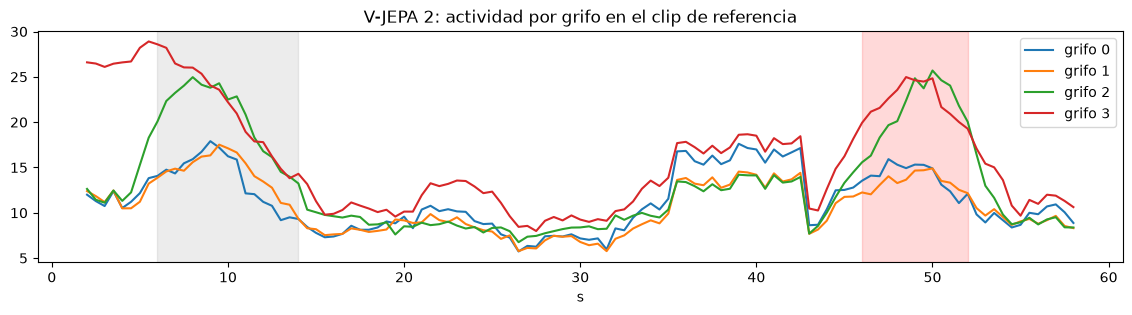

In [27]:
t_ref, G_ref, P_ref = embed_windows(REF_CLIP, STRIDE)
y_ref, keep_ref = label_times(t_ref, EVENTS, IGNORE)
X_ref = window_feats(G_ref, P_ref)
np.savez(f'{OUT}/ref_{REF_CLIP}.npz', t=t_ref, G=G_ref, P=P_ref)
print(f'{len(t_ref)} ventanas | positivas {y_ref[keep_ref].sum()} | negativas {(1 - y_ref[keep_ref]).sum()} | ignoradas {(~keep_ref).sum()}')

d = np.linalg.norm(P_ref - np.median(P_ref, 0, keepdims=True), axis=2)
plt.figure(figsize=(14, 3)); plt.plot(t_ref, d); plt.legend([f'grifo {i}' for i in range(d.shape[1])])
for a, b in EVENTS: plt.axvspan(a, b, color='red', alpha=.15)
for a, b in IGNORE: plt.axvspan(a, b, color='grey', alpha=.15)
plt.title('V-JEPA 2: actividad por grifo en el clip de referencia'); plt.xlabel('s'); plt.show()

## 4 · Entrenar y medir dentro del clip

Ventanas vecinas se solapan y son casi iguales, así que un *leave-one-out* normal haría trampa. Para predecir cada ventana entrenamos **sin las ventanas a menos de 2 s** de ella (`GAP`). Comparamos dos modelos:
- **Regresión logística** sobre las features de la ventana.
- **Prototipo**: similitud coseno con la media de las ventanas positivas menos la de las negativas (sin entrenamiento, el más simple).

,n,positivos,prevalencia,AP,ROC_AUC,precision,recall,F1,F1_umbral_opt
logística,97.000000,12.000000,0.124,0.896,0.985,0.750,1.000,0.857,0.857
prototipo,97.000000,12.000000,0.124,0.956,0.994,0.444,1.000,0.615,0.923


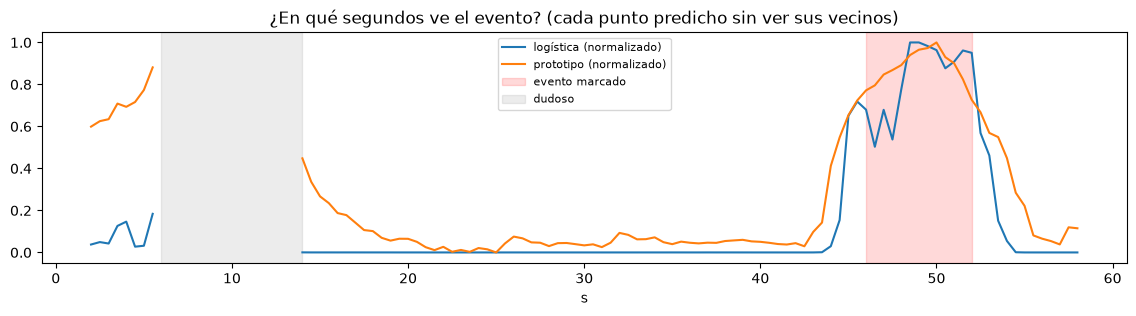

In [28]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (average_precision_score, roc_auc_score, f1_score, precision_score, recall_score,
                             precision_recall_curve, confusion_matrix, ConfusionMatrixDisplay)
GAP = 2.0

def make_lr():
    return make_pipeline(StandardScaler(), LogisticRegression(C=0.05, max_iter=5000, class_weight='balanced'))

class Prototype:
    def fit(self, X, y):
        Xn = X / (np.linalg.norm(X, axis=1, keepdims=True) + 1e-9)
        self.w = Xn[y == 1].mean(0) - Xn[y == 0].mean(0); return self
    def score(self, X):
        Xn = X / (np.linalg.norm(X, axis=1, keepdims=True) + 1e-9); return Xn @ self.w

def loo_gap(X, y, t, keep, kind):
    p = np.full(len(y), np.nan)
    for i in np.where(keep)[0]:
        tr = keep & (np.abs(t - t[i]) > GAP)
        if y[tr].min() == y[tr].max(): continue
        if kind == 'lr': p[i] = make_lr().fit(X[tr], y[tr]).predict_proba(X[i:i + 1])[0, 1]
        else:            p[i] = Prototype().fit(X[tr], y[tr]).score(X[i:i + 1])[0]
    return p

def metrics(y, p, thr):
    ok = ~np.isnan(p); y, p = y[ok], p[ok]
    pr, rc, th = precision_recall_curve(y, p); f = 2 * pr * rc / (pr + rc + 1e-9)
    return dict(n=len(y), positivos=int(y.sum()), prevalencia=y.mean(), AP=average_precision_score(y, p),
                ROC_AUC=roc_auc_score(y, p), precision=precision_score(y, p > thr, zero_division=0),
                recall=recall_score(y, p > thr), F1=f1_score(y, p > thr), F1_umbral_opt=f[:-1].max())

P_IN = {'logística': loo_gap(X_ref, y_ref, t_ref, keep_ref, 'lr'), 'prototipo': loo_gap(X_ref, y_ref, t_ref, keep_ref, 'proto')}
MET_IN = pd.DataFrame({k: metrics(y_ref, v, 0.5 if k == 'logística' else 0.0) for k, v in P_IN.items()}).T
display(MET_IN.style.format('{:.3f}', subset=['prevalencia', 'AP', 'ROC_AUC', 'precision', 'recall', 'F1', 'F1_umbral_opt']))

fig, ax = plt.subplots(figsize=(14, 3))
for k, v in P_IN.items():
    vv = (v - np.nanmin(v)) / (np.nanmax(v) - np.nanmin(v) + 1e-9); ax.plot(t_ref, vv, label=f'{k} (normalizado)')
for a, b in EVENTS: ax.axvspan(a, b, color='red', alpha=.15, label='evento marcado')
for a, b in IGNORE: ax.axvspan(a, b, color='grey', alpha=.15, label='dudoso')
ax.set_xlabel('s'); ax.legend(fontsize=8); ax.set_title('¿En qué segundos ve el evento? (cada punto predicho sin ver sus vecinos)'); plt.show()

## 5 · La prueba de verdad: otros clips de bar_05

Entrenamos con **todas** las ventanas del clip de referencia y escaneamos otros clips del mismo bar (misma cámara): todos los `un_vaso_dos_grifos` y `N_NEG_SCAN` del resto. La puntuación de un clip es la de su ventana más alta. Si el detector ha aprendido el evento y no el clip, los positivos deben salir arriba.

Coste: ~60 ventanas por clip; en una T4, unos 15–30 s por clip, así que ~80 clips son 20–40 min. Se guarda en Drive y se puede reanudar.

In [ ]:
cand = train[(train.bar == BAR) & (train.clip_id != REF_CLIP)]
scan = pd.concat([cand[cand.label == TARGET], cand[cand.label != TARGET].sample(min(N_NEG_SCAN, (cand.label != TARGET).sum()), random_state=0)])
ok = fetch(list(scan.clip_id)); scan = scan[scan.clip_id.isin(ok)].reset_index(drop=True)
scan['y'] = (scan.label == TARGET).astype(int)
print(len(scan), 'clips a escanear |', scan.y.sum(), 'positivos')
assert scan.y.sum() > 0 and (scan.y == 0).sum() > 0, (
    f'No hay clips de {BAR} para escanear en tu Drive (encontrados: {len(scan)}). Si aún se están descomprimiendo, '
    'espera a que termine y vuelve a ejecutar esta celda. Si ya están, comprueba que la carpeta con los .mp4 está dentro de DRIVE.')

# entrenamos con el clip de referencia (+ los clips extra marcados a mano, si hay)
Xtr, ytr = [X_ref[keep_ref]], [y_ref[keep_ref]]
for cid, ev in EXTRA_LABELED.items():
    fetch([cid]); t_, G_, P_ = embed_windows(cid, STRIDE); y_, k_ = label_times(t_, ev)
    Xtr.append(window_feats(G_, P_)); ytr.append(y_)
Xtr, ytr = np.vstack(Xtr), np.concatenate(ytr)
lr = make_lr().fit(Xtr, ytr); proto = Prototype().fit(Xtr, ytr)

SCAN_DIR = pathlib.Path(OUT, 'scan'); SCAN_DIR.mkdir(exist_ok=True)
CURVES = {}
for r in tqdm(scan.itertuples(), total=len(scan)):
    f = SCAN_DIR / f'{r.clip_id}.npz'
    if f.exists(): z = np.load(f); t_, G_, P_ = z['t'], z['G'], z['P']
    else: t_, G_, P_ = embed_windows(r.clip_id, STRIDE_SCAN); np.savez(f, t=t_, G=G_, P=P_)
    X_ = window_feats(G_, P_)
    CURVES[r.clip_id] = (t_, lr.predict_proba(X_)[:, 1], proto.score(X_))
scan['p_logistica'] = [CURVES[c][1].max() for c in scan.clip_id]
scan['p_prototipo'] = [CURVES[c][2].max() for c in scan.clip_id]
scan['t_pico'] = [CURVES[c][0][CURVES[c][1].argmax()] for c in scan.clip_id]
scan.to_csv(f'{OUT}/scan_{BAR}.csv', index=False)

81 clips a escanear | 21 positivos


  0%|          | 0/81 [00:00<?, ?it/s]

## 6 · Métricas fuera del clip

- **Prevalencia** = AP del azar. Lo que importa es cuánto lo supera la AP.
- **F1 @ 0,5** es el número honesto (umbral fijado sin mirar estos clips); **F1 @ umbral óptimo** es optimista, solo para ver el techo.
- La tabla por etiqueta dice con qué se confunde: si `servir_y_rellenar` o `normal` con varias cervezas salen altos, es que ha aprendido "manos en los grifos" y no "un vaso en dos grifos".

In [ ]:
thr_proto = np.median(proto.score(Xtr[ytr == 1]))   # umbral del prototipo fijado en train
MET_OUT = pd.DataFrame({'logística': metrics(scan.y.values, scan.p_logistica.values, 0.5),
                        'prototipo': metrics(scan.y.values, scan.p_prototipo.values, thr_proto)}).T
display(MET_OUT.style.format('{:.3f}', subset=['prevalencia', 'AP', 'ROC_AUC', 'precision', 'recall', 'F1', 'F1_umbral_opt']))
pd.concat({'dentro del clip': MET_IN, 'otros clips de ' + BAR: MET_OUT}).to_csv(f'{OUT}/metricas.csv')

fig, axs = plt.subplots(1, 3, figsize=(17, 4))
ConfusionMatrixDisplay(confusion_matrix(scan.y, scan.p_logistica > .5, labels=[0, 1]), display_labels=['resto', 'dos grifos']).plot(ax=axs[0], colorbar=False)
axs[0].set_title('logística, umbral 0,5')
for k, col, ax in [('logística', 'p_logistica', axs[1]), ('prototipo', 'p_prototipo', axs[2])]:
    ax.hist(scan.loc[scan.y == 0, col], bins=20, alpha=.6, label='resto', density=True)
    ax.hist(scan.loc[scan.y == 1, col], bins=20, alpha=.6, label='dos grifos', density=True); ax.set_title(k); ax.legend()
plt.tight_layout(); plt.show()

display(scan.groupby('label')[['p_logistica', 'p_prototipo']].mean().sort_values('p_logistica', ascending=False))

In [ ]:
# Revisar: los positivos con más y menos puntuación, y los negativos con más (falsos positivos).
# Mira el segundo del pico: si en un positivo cae en el evento, lo ha encontrado de verdad.
show = pd.concat([scan[scan.y == 1].nlargest(2, 'p_logistica'), scan[scan.y == 1].nsmallest(2, 'p_logistica'),
                  scan[scan.y == 0].nlargest(2, 'p_logistica')])
for r in show.itertuples():
    t_, pl, pp = CURVES[r.clip_id]
    plt.figure(figsize=(14, 2)); plt.plot(t_, pl); plt.ylim(0, 1)
    plt.title(f'{r.clip_id} · {r.label} · score {r.p_logistica:.2f} · pico {r.t_pico:.0f}s'); plt.show()
    contact(r.clip_id, max(0, r.t_pico - 4), r.t_pico + 4, step=1.0)

## 6b · Veredicto: ¿ha detectado la mala praxis?

`veredicto(clip)` responde en claro para un clip: **SÍ / NO** hay "un vaso, dos grifos", **en qué segundos** y con qué confianza. Se puede pasar un `clip_id` del dataset o la ruta de cualquier `.mp4` de este bar (por ejemplo uno que subas a Colab). Si el clip está en `train.csv`, dice además si el veredicto coincide con la etiqueta humana.

El umbral es `UMBRAL` (0,5 por defecto). Subirlo da menos falsas alarmas pero se escapan más casos; la tabla del paso 6 te dice qué pasa con cada valor.

In [ ]:
UMBRAL = 0.5
MIN_DUR = 1.0      # segundos seguidos por encima del umbral para dar el evento por detectado

def segmentos(t, p, thr, step):
    # agrupa ventanas seguidas por encima del umbral en intervalos (inicio, fin, prob. máxima)
    segs, cur = [], None
    for ti, pi in zip(t, p):
        if pi >= thr:
            cur = [ti - step / 2, ti + step / 2, pi] if cur is None else [cur[0], ti + step / 2, max(cur[2], pi)]
        elif cur is not None:
            segs.append(tuple(cur)); cur = None
    if cur is not None: segs.append(tuple(cur))
    return [sg for sg in segs if sg[1] - sg[0] >= MIN_DUR]

def veredicto(clip, mostrar=True, umbral=None):
    thr = UMBRAL if umbral is None else umbral
    path = pathlib.Path(clip)
    if path.suffix == '.mp4' and path.exists():
        cid = path.stem
        if not (CLIPS / path.name).exists(): shutil.copy(path, CLIPS / path.name)
    else:
        cid = clip; assert fetch([cid]), f'No encuentro {cid}.mp4'
    if cid in CURVES: t_, p_, _ = CURVES[cid]
    elif cid == REF_CLIP: t_, p_ = t_ref, lr.predict_proba(X_ref)[:, 1]
    else:
        t_, G_, P_ = embed_windows(cid, STRIDE_SCAN); p_ = lr.predict_proba(window_feats(G_, P_))[:, 1]
    step = np.median(np.diff(t_)) if len(t_) > 1 else 1.0
    segs = segmentos(t_, p_, thr, step)
    hay = len(segs) > 0
    real = train.loc[train.clip_id == cid, 'label']
    real = real.iloc[0] if len(real) else None
    acierto = None if real is None else (hay == (real == TARGET))
    if mostrar:
        if hay:
            donde = ', '.join(f'{a:.0f}–{b:.0f} s (confianza {c:.0%})' for a, b, c in segs)
            print(f'✅ {cid}: SÍ, detectada mala praxis "un vaso, dos grifos" en {donde}')
        else:
            print(f'⛔ {cid}: NO detectada (confianza máxima {p_.max():.0%}, umbral {thr:.0%})')
        if real is not None:
            print(f'   etiqueta humana: {real} → {"ACIERTO" if acierto else "FALLO"}')
        plt.figure(figsize=(14, 2.2)); plt.plot(t_, p_); plt.axhline(thr, color='k', ls='--', lw=.8); plt.ylim(0, 1)
        for a, b, c in segs: plt.axvspan(a, b, color='red', alpha=.2)
        plt.title(f'{cid} · probabilidad de "un vaso, dos grifos" por segundo'); plt.xlabel('s'); plt.show()
        if hay:
            a, b, _ = max(segs, key=lambda sg: sg[2]); contact(cid, max(0, a - 2), b + 2, step=0.5)
    return dict(clip_id=cid, detectado=hay, prob_max=float(p_.max()),
                segmentos='; '.join(f'{a:.0f}-{b:.0f}s' for a, b, _ in segs), etiqueta=real, acierto=acierto)

veredicto(REF_CLIP)

In [ ]:
# Veredicto para todos los clips escaneados: cuántos acierta y cuáles falla
VER = pd.DataFrame([veredicto(c, mostrar=False) for c in scan.clip_id])
VER['tipo'] = np.select([VER.detectado & (VER.etiqueta == TARGET), ~VER.detectado & (VER.etiqueta != TARGET),
                         VER.detectado & (VER.etiqueta != TARGET)],
                        ['acierto: detectado', 'acierto: no hay', 'falsa alarma'], 'se le escapó')
print(VER.tipo.value_counts().to_string()); print(f'aciertos: {VER.acierto.mean():.0%}')
VER.to_csv(f'{OUT}/veredictos_{BAR}.csv', index=False)
display(VER.sort_values('prob_max', ascending=False).head(20))

In [ ]:
# Prueba con cualquier clip: un clip_id del dataset o la ruta de un .mp4 (de este mismo bar)
# veredicto('6974f59306bf')
# veredicto('/content/mi_video.mp4')

## 7 · Siguiente paso: unos pocos clips más

Si fuera del clip sale flojo, lo más rentable no es todo el dataset sino **3–5 clips más marcados a mano**: coge los positivos mejor puntuados del paso 6, comprueba en la hoja de contactos en qué segundos está el evento y añádelos a `EXTRA_LABELED` en la celda 0, por ejemplo `{'6974f59306bf': [(20, 27)]}`. Vuelve a ejecutar desde el paso 5: las ventanas ya calculadas se reutilizan. Así se ve cuántos ejemplos hacen falta por bar, que es justo la pregunta del reto sobre un bar nuevo.